# Análisis exploratorio de datos - House Pricing

Exploración inicial de los datasets de entrenamiento y prueba para entender la estructura de la información y el comportamiento de la variable objetivo `SalePrice`.

## 1. Librerías

Importación de las librerías PyData utilizadas para manipulación de datos, cálculo numérico, estadística y visualización.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import sklearn

## 2. Carga de datos

Lectura de los datasets de entrenamiento y prueba. La ruta y los nombres de archivo se definen en variables para poder cambiar la fuente sin modificar el resto del código. Por defecto, los datos se leen desde `data/raw/`.

In [2]:
from house_pricing.config import RAW_DATA_DIR

# Cambiar estas variables si la ubicación o el nombre de los archivos varía
DATA_PATH = RAW_DATA_DIR
TRAIN_FILE = "train.csv"
TEST_FILE = "test.csv"

train = pd.read_csv(DATA_PATH / TRAIN_FILE)
test = pd.read_csv(DATA_PATH / TEST_FILE)

print(f"Train: {train.shape}")
print(f"Test: {test.shape}")

2026-10-27 19:36:44.652 | INFO     | house_pricing.config:<module>:11 - PROJ_ROOT path is: C:\Users\MO\Desktop\Business Intelligence\8vo. trimestre\Product_Development\Clase\House_pricing


Train: (1460, 81)
Test: (1459, 80)


## 3. Análisis de la variable objetivo

Distribución de `SalePrice` mediante una gráfica de densidad, para identificar su forma, asimetría y posibles valores extremos.

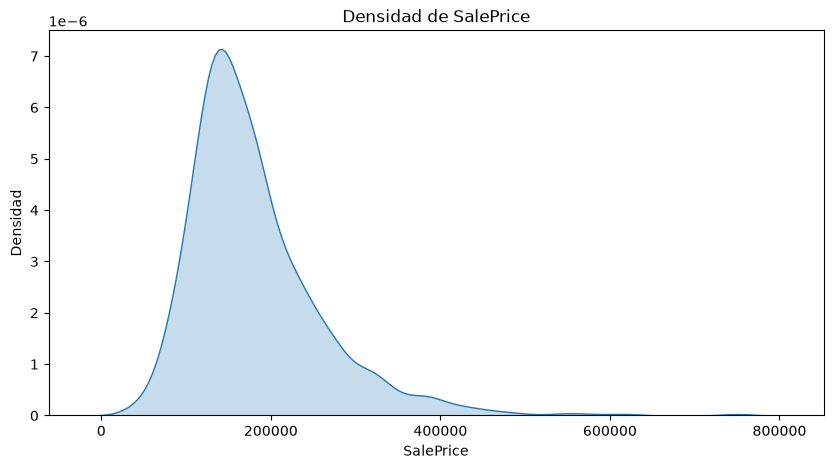

In [3]:
TARGET = "SalePrice"

fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(data=train, x=TARGET, fill=True, ax=ax)
ax.set_title(f"Densidad de {TARGET}")
ax.set_xlabel(TARGET)
ax.set_ylabel("Densidad")
plt.show()

## 4. Clasificación de variables numéricas

Separación de las variables numéricas en dos grupos según su número de valores únicos: **discretas** (hasta `DISCRETE_THRESHOLD` valores distintos, como conteos, calificaciones o fechas en mes/año) y **continuas** (el resto). Se excluye la columna `Id` por ser un identificador.

In [6]:
DISCRETE_THRESHOLD = 15

numeric_cols = train.select_dtypes(include="number").columns.drop(["Id", TARGET])
n_unique = train[numeric_cols].nunique()

discretas = n_unique[n_unique <= DISCRETE_THRESHOLD].index.tolist()
continuas = n_unique[n_unique > DISCRETE_THRESHOLD].index.tolist()

print(f"Discretas ({len(discretas)}): {discretas}")
print(f"Continuas ({len(continuas)}): {continuas}")

Discretas (15): ['MSSubClass', 'OverallQual', 'OverallCond', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'PoolArea', 'MoSold', 'YrSold']
Continuas (21): ['LotFrontage', 'LotArea', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageYrBlt', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'MiscVal']


## 5. Relación de las variables continuas con la variable objetivo

Scatterplot de cada variable continua contra `SalePrice` para identificar relaciones lineales, no lineales y valores atípicos. El título de cada gráfica incluye el coeficiente de correlación de Pearson (`r`).

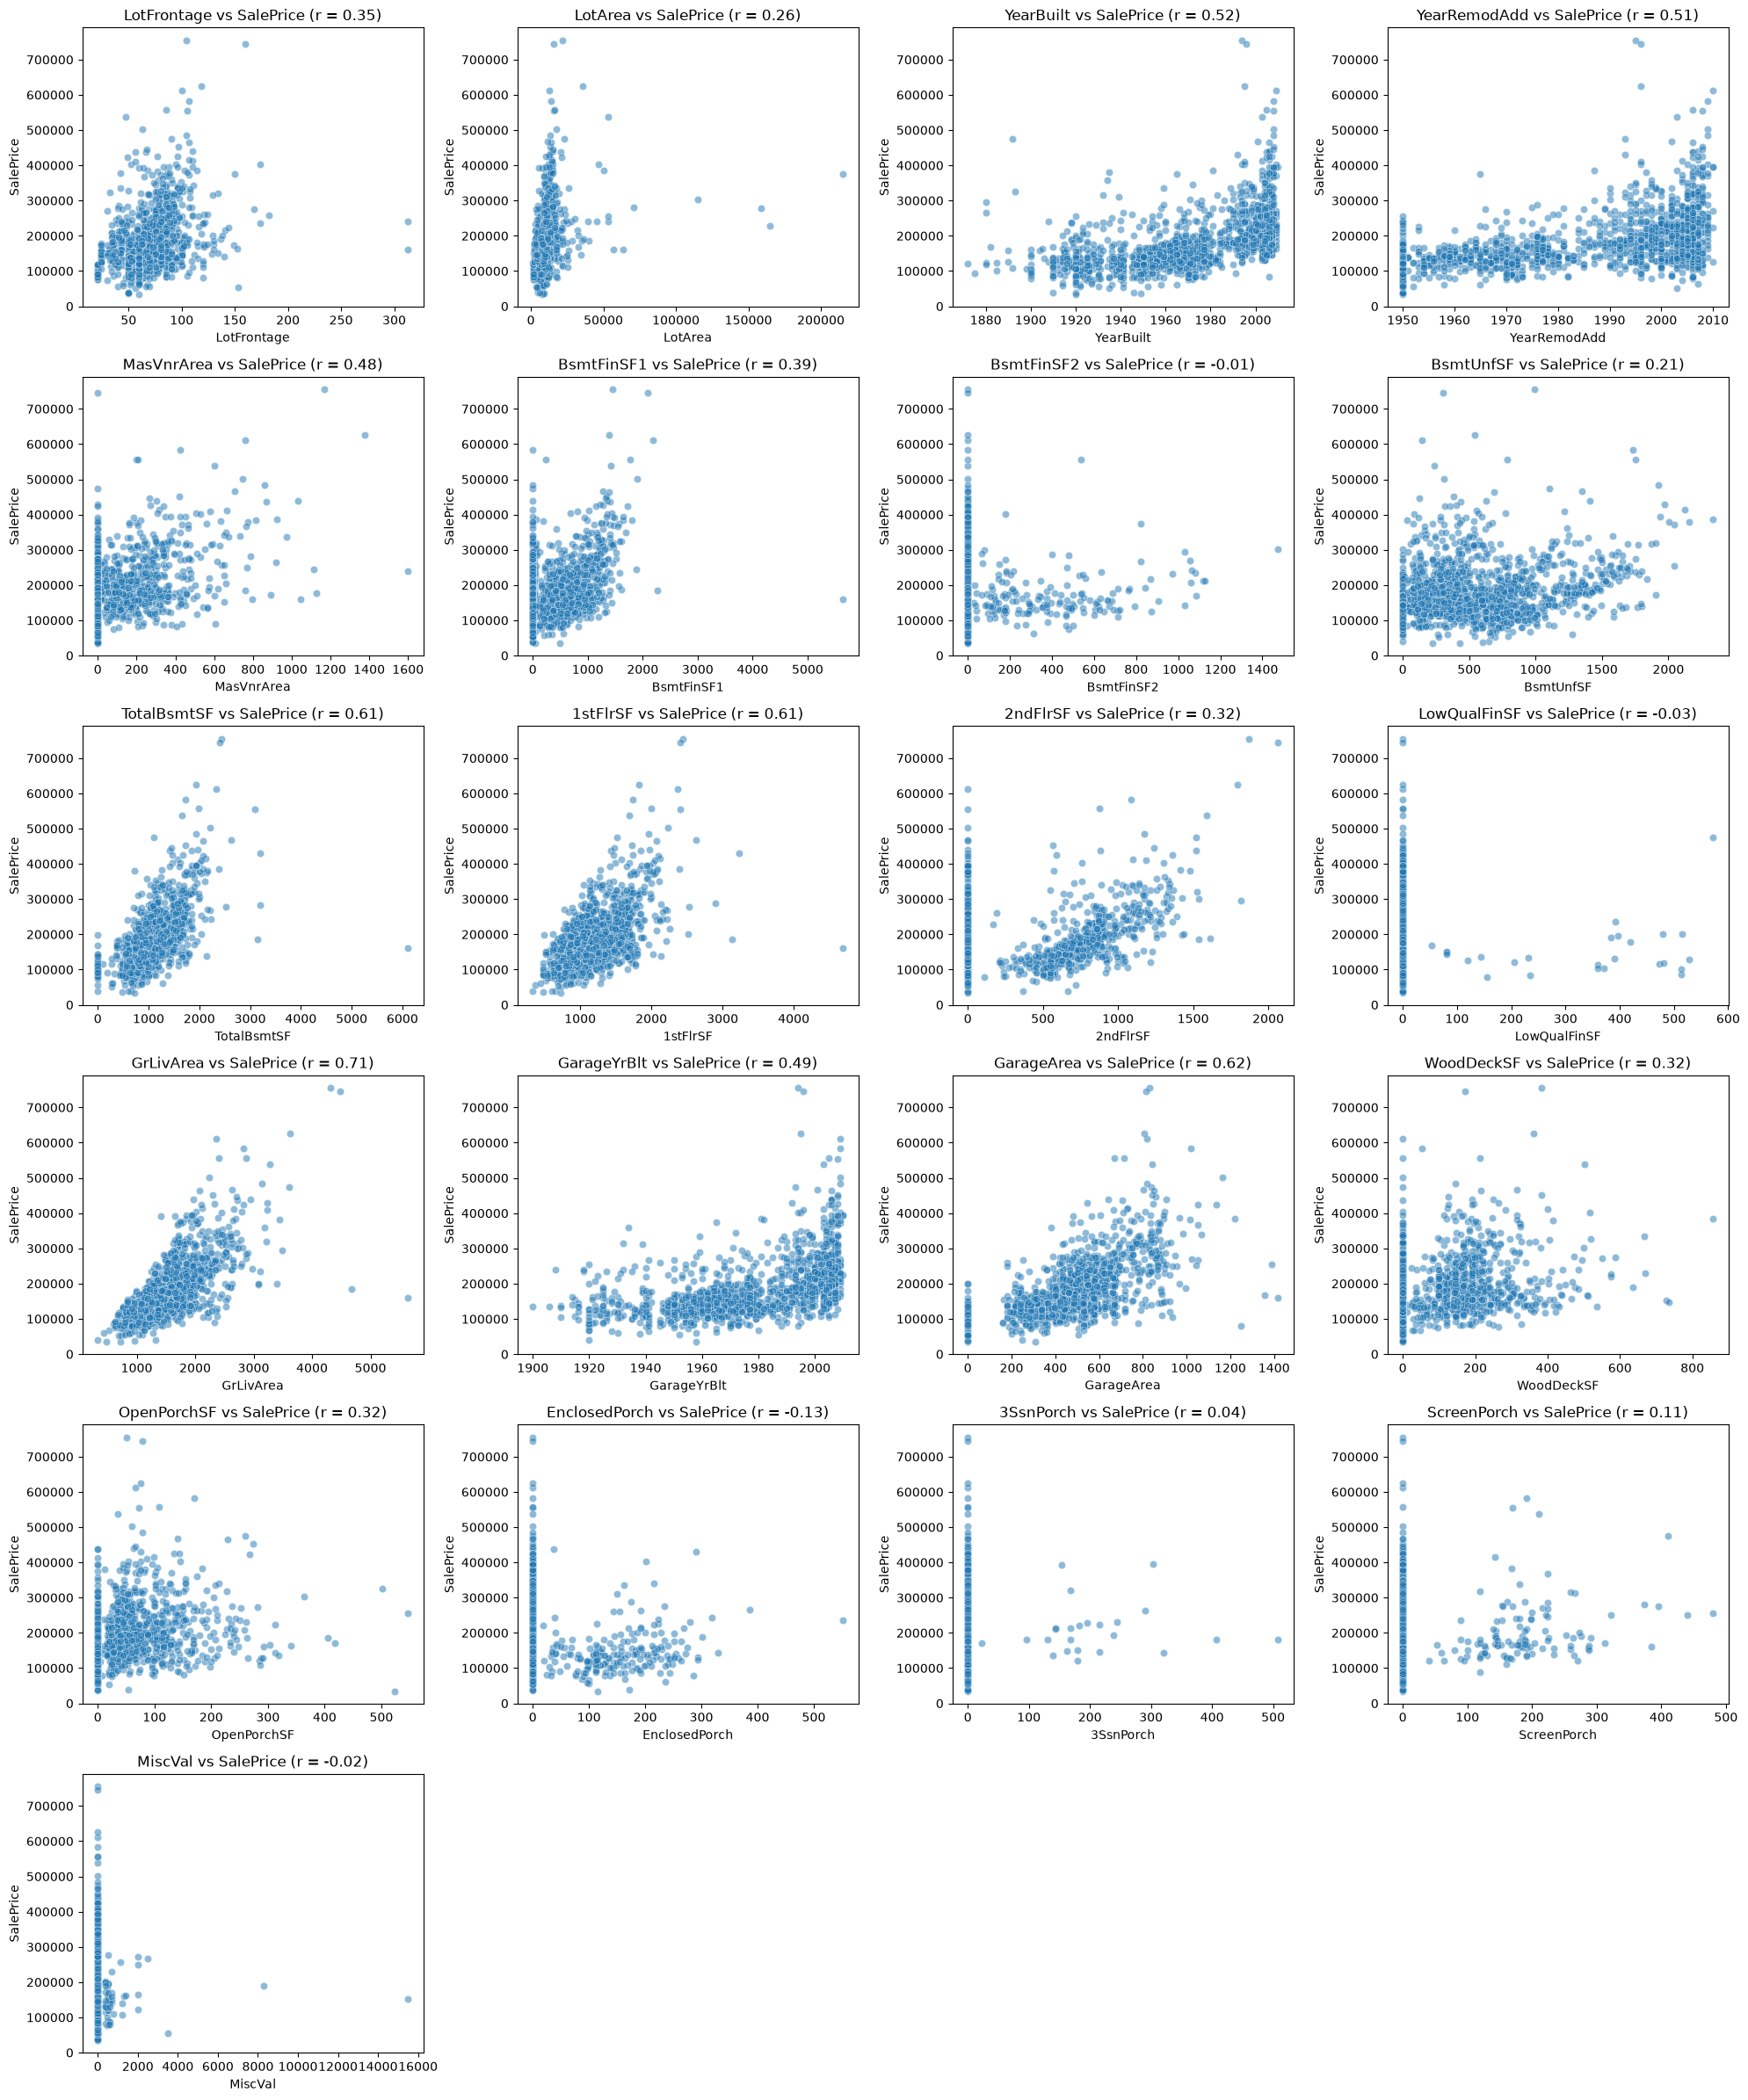

In [7]:
correlations = train[continuas].corrwith(train[TARGET])

N_COLS = 4
n_rows = int(np.ceil(len(continuas) / N_COLS))
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(5 * N_COLS, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, continuas):
    sns.scatterplot(data=train, x=col, y=TARGET, alpha=0.5, ax=ax)
    ax.set_title(f"{col} vs {TARGET} (r = {correlations[col]:.2f})")

# Ocultar los ejes sobrantes de la cuadrícula
for ax in axes[len(continuas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### 5.1 Ranking de correlaciones

Tabla con el coeficiente de correlación de cada variable continua respecto a `SalePrice`, ordenada de mayor a menor. La columna `fuerza` clasifica la relación según el valor absoluto de la métrica: **Fuerte** (≥ 0.5), **Moderada** (≥ 0.3) y **Débil** (< 0.3).

In [16]:
def classify_strength(value):
    """Clasifica la fuerza de la relación según el valor absoluto de la métrica."""
    if abs(value) >= 0.5:
        return "Fuerte"
    if abs(value) >= 0.3:
        return "Moderada"
    return "Débil"


corr_df = (
    correlations.sort_values(ascending=False)
    .rename("correlacion")
    .rename_axis("variable")
    .reset_index()
)
corr_df["fuerza"] = corr_df["correlacion"].apply(classify_strength)
corr_df

,variable,correlacion,fuerza
0,GrLivArea,0.708624,Fuerte
1,GarageArea,0.623431,Fuerte
2,TotalBsmtSF,0.613581,Fuerte
3,1stFlrSF,0.605852,Fuerte
4,YearBuilt,0.522897,Fuerte
5,YearRemodAdd,0.507101,Fuerte
6,GarageYrBlt,0.486362,Moderada
7,MasVnrArea,0.477493,Moderada
8,BsmtFinSF1,0.386420,Moderada
9,LotFrontage,0.351799,Moderada


## 6. Relación de las variables discretas con la variable objetivo

Boxplot de `SalePrice` por cada valor de las variables discretas, para comparar la mediana y la dispersión del precio entre categorías. Sobre cada caja se superponen las observaciones individuales (stripplot) para visualizar cuántos registros tiene cada categoría y dónde se concentran.

El título de cada gráfica incluye la **razón de correlación (η, eta)**, el equivalente a la correlación para una variable agrupada en categorías frente a una numérica:

$$\eta = \sqrt{\frac{\sum_{k} n_k (\bar{y}_k - \bar{y})^2}{\sum_{i} (y_i - \bar{y})^2}}$$

donde $\bar{y}_k$ y $n_k$ son la media y el número de observaciones de la categoría $k$, y $\bar{y}$ es la media global de `SalePrice`. Toma valores entre 0 (la variable no explica el precio) y 1 (la variable determina el precio por completo). $\eta^2$ es la proporción de la varianza del precio explicada por la variable.

Se utiliza η en lugar de Pearson porque captura relaciones no lineales y variables que son códigos sin orden numérico, como `MSSubClass`.

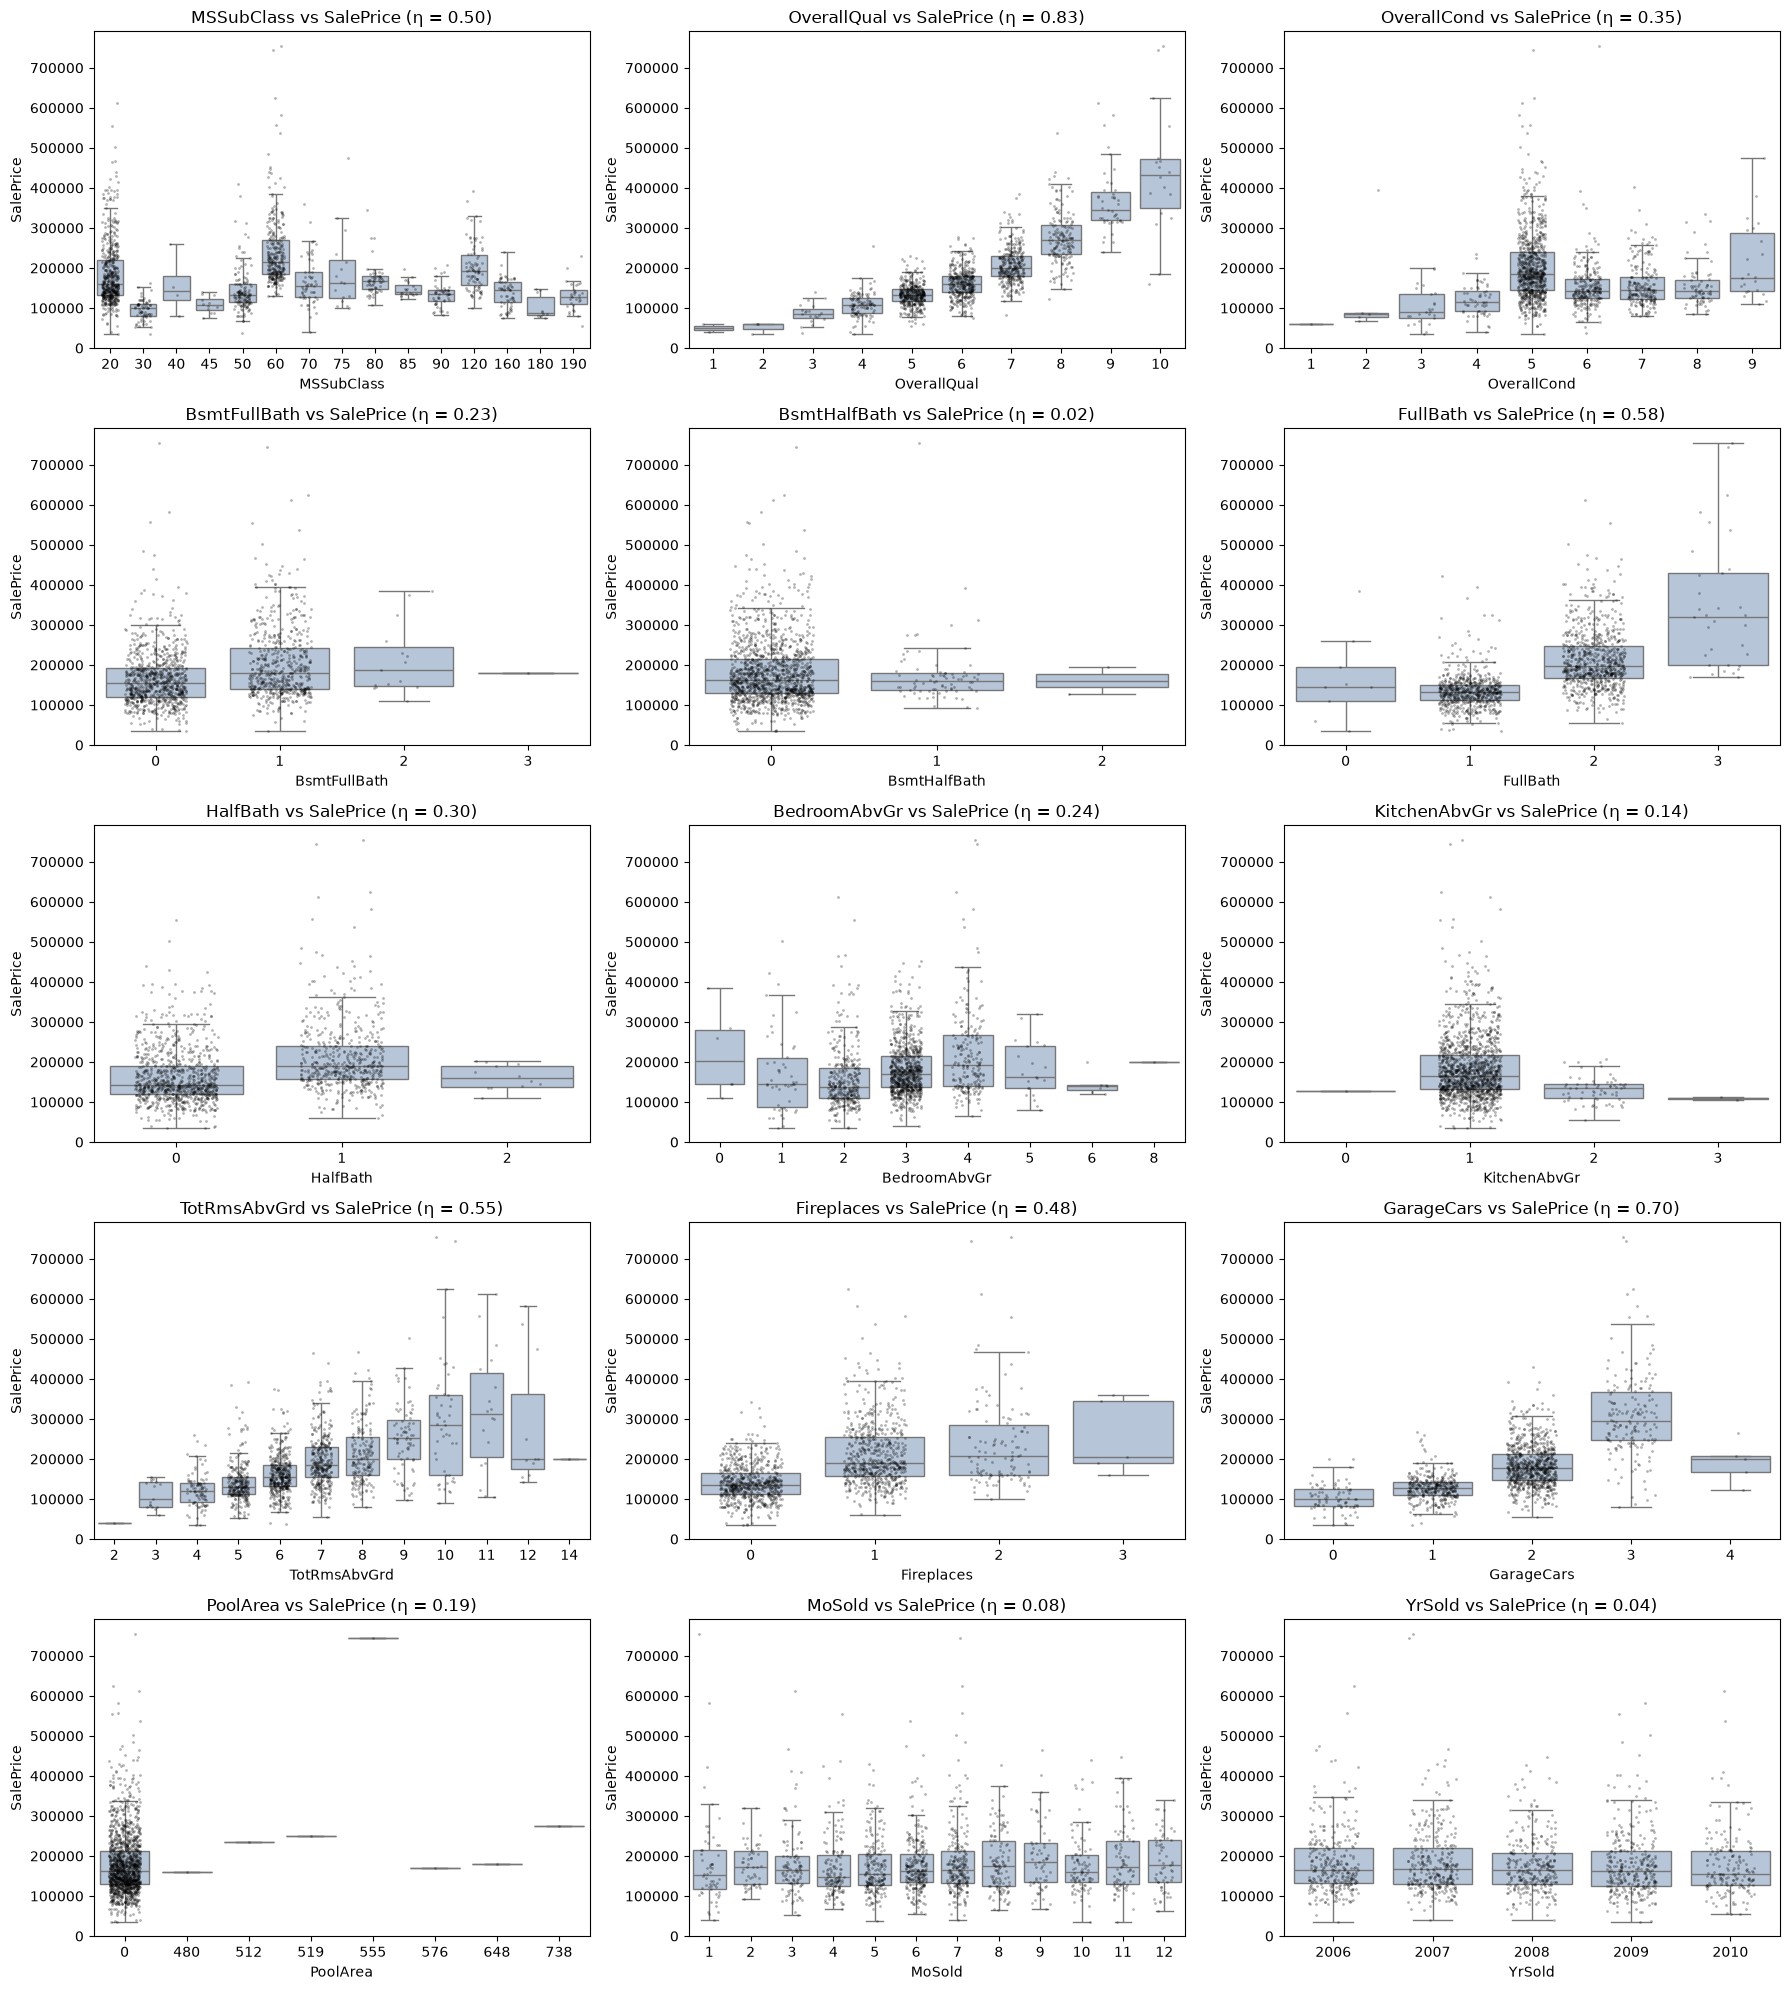

In [17]:
def correlation_ratio(categories, values):
    """Razón de correlación (eta) entre una variable categórica y una numérica."""
    grand_mean = values.mean()
    groups = values.groupby(categories)
    ss_between = (groups.count() * (groups.mean() - grand_mean) ** 2).sum()
    ss_total = ((values - grand_mean) ** 2).sum()
    return np.sqrt(ss_between / ss_total)


etas_discretas = pd.Series({col: correlation_ratio(train[col], train[TARGET]) for col in discretas})

N_COLS = 3
n_rows = int(np.ceil(len(discretas) / N_COLS))
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(6 * N_COLS, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, discretas):
    # showfliers=False evita duplicar los atípicos, ya que el stripplot muestra todos los puntos
    sns.boxplot(data=train, x=col, y=TARGET, showfliers=False, color="lightsteelblue", ax=ax)
    sns.stripplot(data=train, x=col, y=TARGET, color="black", alpha=0.3, size=2, jitter=0.25, ax=ax)
    ax.set_title(f"{col} vs {TARGET} (η = {etas_discretas[col]:.2f})")

# Ocultar los ejes sobrantes de la cuadrícula
for ax in axes[len(discretas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### 6.1 Ranking de razón de correlación

Tabla con el valor de η de cada variable discreta respecto a `SalePrice`, ordenada de mayor a menor, con la misma clasificación de fuerza utilizada para las variables continuas.

In [18]:
eta_discretas_df = (
    etas_discretas.sort_values(ascending=False)
    .rename("eta")
    .rename_axis("variable")
    .reset_index()
)
eta_discretas_df["fuerza"] = eta_discretas_df["eta"].apply(classify_strength)
eta_discretas_df

,variable,eta,fuerza
0,OverallQual,0.827153,Fuerte
1,GarageCars,0.700877,Fuerte
2,FullBath,0.580028,Fuerte
3,TotRmsAbvGrd,0.546867,Fuerte
4,MSSubClass,0.496302,Moderada
5,Fireplaces,0.481828,Moderada
6,OverallCond,0.354105,Moderada
7,HalfBath,0.304537,Moderada
8,BedroomAbvGr,0.242193,Débil
9,BsmtFullBath,0.231361,Débil


## 7. Relación de las variables categóricas con la variable objetivo

Boxplot de `SalePrice` por cada categoría de las variables categóricas, con las observaciones individuales superpuestas. Las categorías se ordenan por mediana del precio y los valores faltantes se agrupan como `"NA"`, ya que en este dataset indican ausencia de la característica (por ejemplo, sin piscina o sin sótano). El título de cada gráfica incluye la razón de correlación (η) definida en la sección 6.

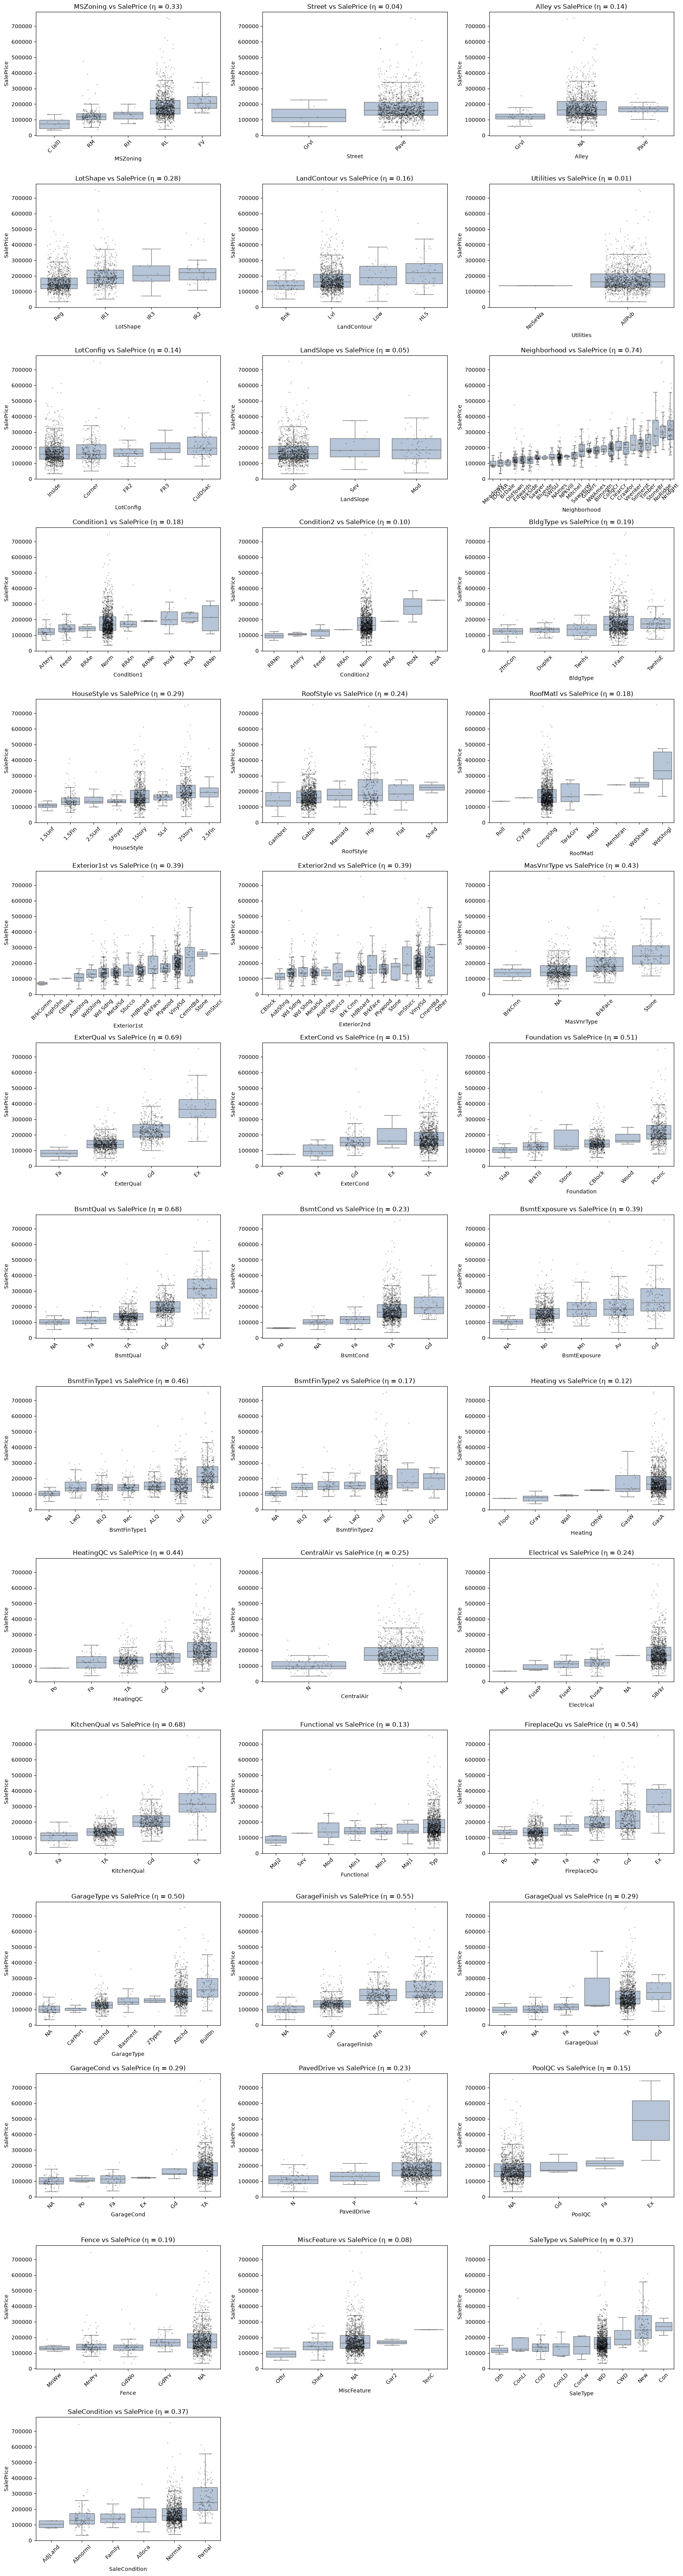

In [19]:
categoricas = train.select_dtypes(include=["object", "str"]).columns.tolist()
train_cat = train[categoricas].fillna("NA")

etas_categoricas = pd.Series({col: correlation_ratio(train_cat[col], train[TARGET]) for col in categoricas})

N_COLS = 3
n_rows = int(np.ceil(len(categoricas) / N_COLS))
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(6 * N_COLS, 4.5 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, categoricas):
    order = train[TARGET].groupby(train_cat[col]).median().sort_values().index
    sns.boxplot(x=train_cat[col], y=train[TARGET], order=order, showfliers=False, color="lightsteelblue", ax=ax)
    sns.stripplot(x=train_cat[col], y=train[TARGET], order=order, color="black", alpha=0.3, size=2, jitter=0.25, ax=ax)
    ax.set_title(f"{col} vs {TARGET} (η = {etas_categoricas[col]:.2f})")
    ax.tick_params(axis="x", rotation=45)

# Ocultar los ejes sobrantes de la cuadrícula
for ax in axes[len(categoricas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### 7.1 Ranking de razón de correlación

Tabla con el valor de η de cada variable categórica respecto a `SalePrice`, ordenada de mayor a menor, con su clasificación de fuerza.

In [20]:
eta_categoricas_df = (
    etas_categoricas.sort_values(ascending=False)
    .rename("eta")
    .rename_axis("variable")
    .reset_index()
)
eta_categoricas_df["fuerza"] = eta_categoricas_df["eta"].apply(classify_strength)
eta_categoricas_df

,variable,eta,fuerza
0,Neighborhood,0.738630,Fuerte
1,ExterQual,0.690933,Fuerte
2,BsmtQual,0.681905,Fuerte
3,KitchenQual,0.675721,Fuerte
4,GarageFinish,0.553059,Fuerte
5,FireplaceQu,0.542181,Fuerte
6,Foundation,0.506328,Fuerte
7,GarageType,0.499204,Moderada
8,BsmtFinType1,0.459141,Moderada
9,HeatingQC,0.442154,Moderada


## 8. Selección de features

Selección de las `TOP_N` variables con mayor relación con `SalePrice` en cada grupo: continuas según el valor absoluto de la correlación de Pearson, y discretas y categóricas según la razón de correlación (η). La unión de los tres grupos forma `modelo_features`, el conjunto de variables para construir el modelo.

In [21]:
TOP_N = 10

top_continuas = correlations.abs().nlargest(TOP_N).index.tolist()
top_discretas = etas_discretas.nlargest(TOP_N).index.tolist()
top_categoricas = etas_categoricas.nlargest(TOP_N).index.tolist()

modelo_features = top_continuas + top_discretas + top_categoricas

print(f"Continuas ({len(top_continuas)}): {top_continuas}")
print(f"Discretas ({len(top_discretas)}): {top_discretas}")
print(f"Categóricas ({len(top_categoricas)}): {top_categoricas}")
print(f"Total de features: {len(modelo_features)}")

Continuas (10): ['GrLivArea', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MasVnrArea', 'BsmtFinSF1', 'LotFrontage']
Discretas (10): ['OverallQual', 'GarageCars', 'FullBath', 'TotRmsAbvGrd', 'MSSubClass', 'Fireplaces', 'OverallCond', 'HalfBath', 'BedroomAbvGr', 'BsmtFullBath']
Categóricas (10): ['Neighborhood', 'ExterQual', 'BsmtQual', 'KitchenQual', 'GarageFinish', 'FireplaceQu', 'Foundation', 'GarageType', 'BsmtFinType1', 'HeatingQC']
Total de features: 30


### 8.1 Exportación a archivo de configuración

Almacenamiento de la variable objetivo y de las features seleccionadas en `pipeline_config.yaml`, en la raíz del proyecto, para que las etapas posteriores del pipeline (creación de features, entrenamiento e inferencia) las lean desde una única fuente.

In [22]:
import yaml

from house_pricing.config import PROJ_ROOT

CONFIG_PATH = PROJ_ROOT / "pipeline_config.yaml"

pipeline_config = {
    "TARGET": TARGET,
    "MODEL_FEATURES": modelo_features,
}

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    yaml.safe_dump(pipeline_config, f, sort_keys=False, allow_unicode=True)

print(f"Configuración guardada en: {CONFIG_PATH}")

Configuración guardada en: C:\Users\MO\Desktop\Business Intelligence\8vo. trimestre\Product_Development\Clase\House_pricing\pipeline_config.yaml
